# Lab 10: Introduction to APIs: Wikipedia

*INFO 4617/5617 · Week 10 · Chapter 10, [Introduction to APIs: Wikipedia](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-10-wikipedia.html)*

Today we code together. Each step below says what we're building and why, and its code cells hold only the comments that frame them: we write the code live, in class. Nothing here is turned in. After most steps, a **⏱ Microsprint** gives you three minutes, alone or with a neighbor, to change one thing and bring a result back to the class. Every step ends with a **💬 Discuss** box of questions to talk over before the next one; click it to open it.

By the end you'll have asked two of Wikipedia's APIs for one article's whole public record: its basic facts, every edit since 2003, its daily readers, who those readers are, and what the article connects to. Then you'll do the same with a client library in a few lines.

**The article:** [University of Colorado Boulder](https://en.wikipedia.org/wiki/University_of_Colorado_Boulder), the chapter's case. You'll choose your own article for the chapter's Recommended Exercises, due Sunday; this lab builds the tools they need.

**Before class:** open this notebook in the `webdata` environment (chapter 1), and have your email address ready for the User-Agent. Step 9 uses mwclient, which `webdata` doesn't include; Step 9 says how to install it.

On Friday, run every cell above where we stopped (**Run → Run All Above Selected Cell**).

> **Instructor key.** Run on 2026-10-21 with `labs/tools/run_key.py`, following the textbook at commit `d9306b7`. Wikipedia's Action API answered 429 (Too Many Requests) to nearly every request during the run, and kept refusing for the next 30 minutes, so these cells are tagged `not-run-live` and have no outputs: Step 3's two pages, `get_revision_batch()` on two articles, and `get_revisions()` on both; all of Step 4 and its microsprint; Step 7's loop, plot, and microsprint; Step 8's first categories request, the backlinks and their loop, and the redirects microsprint; and Step 9 and its microsprint. Run them before class. The refusals were Step 3's Discuss question in practice: the 429 came back as plain text, and `response.json()` stopped with a `JSONDecodeError`. What ran: Steps 0–2 and Step 2's microsprint, Steps 5 and 6, and Step 8's hidden-categories request. A rerun gives the same pageviews (the window ends on 2026-09-30: 2,099 days and 1,367,292 views, as in the chapter) and the same revisions (fixed by `rvstart`, unless some are deleted), but not the same length, categories, backlinks, or redirects, which are the article as it is today.

## Step 0 — Set up (5 minutes)

Import `requests`, `time`, `pandas`, and `matplotlib`. Then define the User-Agent every request will send. Wikimedia's [User-Agent policy](https://foundation.wikimedia.org/wiki/Policy:Wikimedia_Foundation_User-Agent_Policy) asks every client to say who it is and how to reach its operator, in this form: `<client name>/<version> (<contact information>) <library name>/<version>`. Keep the first two parts in `CLIENT`, because Step 9's library adds its own name, and add `requests` and its version for `HEADERS`. A client the [rate limits](https://www.mediawiki.org/wiki/Wikimedia_APIs/Rate_limits) can identify only by its network address gets 10 requests a minute, shared with everyone on that network, which is everyone in this room. One with a User-Agent like this gets 200. We import `time` to pause a second between requests in a loop, with [`time.sleep(1)`](https://docs.python.org/3/library/time.html#time.sleep).

In [1]:
# Import requests, time, pandas (as pd), and matplotlib.pyplot (as plt)
# Define CLIENT as "WebDataScience/1.0 (your-email@colorado.edu)", with your email
# Define HEADERS: a dict whose "User-Agent" is CLIENT, a space, then "python-requests/" and requests.__version__
# Define API, the Action API's address, and ARTICLE, the article's title; print HEADERS
import requests
import time
import pandas as pd
import matplotlib.pyplot as plt

CLIENT = "WebDataScience/1.0 (your-email@colorado.edu)"
HEADERS = {"User-Agent": f"{CLIENT} python-requests/{requests.__version__}"}
API = "https://en.wikipedia.org/w/api.php"
ARTICLE = "University of Colorado Boulder"
print(HEADERS)

{'User-Agent': 'WebDataScience/1.0 (your-email@colorado.edu) python-requests/2.34.2'}


<details>
<summary>💬 Discuss</summary>

- In week 2 we wrote a User-Agent too. What does this one add, and who reads it?
- Why does the rate limit treat everyone in this room as one client, unless each of us says who we are?
- Wikipedia's `robots.txt` (week 2) disallows `/w/`, yet the API lives at `/w/api.php`. Why isn't that a contradiction?

</details>

## Step 1 — One request (5 minutes)

Every request to the MediaWiki [Action API](https://www.mediawiki.org/wiki/API:Action_API) has four parts: the base URL, an `action` (what to do), parameters that narrow it, and a `format`. Build the parameters as a dictionary, and `requests` turns them into the URL. Ask for [`prop=info`](https://www.mediawiki.org/wiki/API:Info), the article's basic facts. Our code assumes the request works, and reads the JSON straight away; the Discuss box asks what happens when it doesn't. The chapter's ["The Anatomy of an API Call"](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-10-wikipedia.html#the-anatomy-of-an-api-call) sends the same request.

In [2]:
# Build params: action=query, titles=ARTICLE, prop=info, format=json
# Send the request with params and HEADERS; read its JSON into data, and print it
params = {"action": "query", "titles": ARTICLE, "prop": "info", "format": "json"}
response = requests.get(API, params=params, headers=HEADERS)
data = response.json()
print(data)

{'batchcomplete': '', 'query': {'pages': {'289672': {'pageid': 289672, 'ns': 0, 'title': 'University of Colorado Boulder', 'contentmodel': 'wikitext', 'pagelanguage': 'en', 'pagelanguagehtmlcode': 'en', 'pagelanguagedir': 'ltr', 'touched': '2026-10-18T22:35:28Z', 'lastrevid': 1380813690, 'length': 95112}}}}


<details>
<summary>💬 Discuss</summary>

- Our first request in week 1 fetched this same article as HTML. What's different about what came back this time?
- Print `response.url`. Where are the four parts of the request in it (week 5's URL anatomy), and which one would you change to ask about another article?
- Our code never looks at `response.status_code`. If Wikipedia answered 403 or 429, which line would fail, and which of those two statuses is about you?

</details>

## Step 2 — Read the JSON one level at a time (7 minutes)

The answer is nested: `data["query"]["pages"]`, then a key that is the page's ID. We don't know the ID in advance, so take the first (and only) value from [`pages.values()`](https://docs.python.org/3/library/stdtypes.html#dict.values). Print the title, the page ID, and the article's length in bytes.

In [3]:
# Go down one level at a time: data -> "query" -> "pages" -> the one page inside
# Print its title, pageid, and length
pages = data["query"]["pages"]
page = list(pages.values())[0]
print(page["title"], page["pageid"], f"{page['length']:,} bytes")

University of Colorado Boulder 289672 95,112 bytes


### ⏱ Microsprint (3 minutes, alone or in pairs)

**Do:** ask `prop=info` about three titles in one request, joined with `|`: the article, its talk page (`Talk:` and the title), and a misspelling of the title. Print each page's key, title, and length. This is the chapter's tour of the talk page, and its warning about missing pages in ["Common Issues to Debug"](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-10-wikipedia.html#common-issues-to-debug).

**Share:** the talk page's length, and what the API did with the misspelling.

In [4]:
# Microsprint: one request about three titles, joined with "|": ARTICLE, "Talk:" + ARTICLE, and a misspelling
# Send it as in Step 1; then for each key and page under ["query"]["pages"], print the key, the title,
#   and the length, or "missing" when there isn't one (page.get("length", "missing"))
titles = [ARTICLE, f"Talk:{ARTICLE}", "University of Colorado Bolder"]
params = {"action": "query", "titles": "|".join(titles), "prop": "info", "format": "json"}
response = requests.get(API, params=params, headers=HEADERS)
data = response.json()
for key, page in data["query"]["pages"].items():
    print(key, page["title"], page.get("length", "missing"))

-1 University of Colorado Bolder missing
289672 University of Colorado Boulder 95112
2634293 Talk:University of Colorado Boulder 682


<details>
<summary>💬 Discuss</summary>

- Why is the page ID a key rather than a value? What key did the misspelled title get, and what would `page["pageid"]` do with it?
- In week 6 we scraped Wikipedia infoboxes with BeautifulSoup. Which approach breaks first when Wikipedia redesigns its pages?
- The talk page is short, though editors have argued on it for years. Where did its discussions go, and what would you need to know before comparing two pages by length?

</details>

## Step 3 — Every edit, a page at a time (16 minutes)

[`prop=revisions`](https://www.mediawiki.org/wiki/API:Revisions) returns an article's edits, newest first, at most 500 per request (`rvlimit=max`). When there are more, the response carries a [`"continue"`](https://www.mediawiki.org/wiki/API:Continue) key: add its contents to your parameters and ask again, until it's gone. Forgetting this is the most common API bug there is, because the first batch looks like a complete answer. `rvstart` fixes the newest edit we'll accept, `2026-09-30T23:59:59Z`, so that running this next week gives today's answer.

We build it in three moves: two pages by hand; one batch as a function; then the chapter's `get_revisions()`, which follows `"continue"` to the end. The chapter's "Getting Revisions" and "Understanding Pagination" have more.

**Move 1 — two pages by hand.** Ask for page one, and print its `"continue"`. Then add that to the parameters, and ask for page two.

In [ ]:
# Build params: action=query, titles=ARTICLE, prop=revisions, rvprop="ids|timestamp|user|size|comment",
#   rvlimit="max", rvstart="2026-09-30T23:59:59Z", format=json
# Request page one, and go down to the page as in Step 2
# Print how many revisions came back and the last (oldest) one's timestamp; then print data["continue"]
params = {"action": "query", "titles": ARTICLE, "prop": "revisions",
          "rvprop": "ids|timestamp|user|size|comment",
          "rvlimit": "max", "rvstart": "2026-09-30T23:59:59Z", "format": "json"}
response = requests.get(API, params=params, headers=HEADERS)
data = response.json()
page = list(data["query"]["pages"].values())[0]
print(len(page["revisions"]), "revisions, back to", page["revisions"][-1]["timestamp"])
print(data["continue"])

In [ ]:
# Request page two: add data["continue"] to params with params.update(), then request again
# Print the same two lines: how many, back to when, and the new "continue"
params.update(data["continue"])
response = requests.get(API, params=params, headers=HEADERS)
data = response.json()
page = list(data["query"]["pages"].values())[0]
print(len(page["revisions"]), "revisions, back to", page["revisions"][-1]["timestamp"])
print(data["continue"])

**Move 2 — one batch, as a function.** We'll want the first batch of more than one article, so gather page one's lines into `get_revision_batch(title)`, which returns up to 500 revisions as a DataFrame. Try it on the article and on [Boulder, Colorado](https://en.wikipedia.org/wiki/Boulder,_Colorado), the chapter's second case.

In [7]:
# Define get_revision_batch(title): page one's lines, for any title
#   (build params, request, go down to the page), returning page["revisions"] as a DataFrame
def get_revision_batch(title):
    params = {"action": "query", "titles": title, "prop": "revisions",
              "rvprop": "ids|timestamp|user|size|comment",
              "rvlimit": "max", "rvstart": "2026-09-30T23:59:59Z", "format": "json"}
    response = requests.get(API, params=params, headers=HEADERS)
    data = response.json()
    page = list(data["query"]["pages"].values())[0]
    return pd.DataFrame(page["revisions"])

In [ ]:
# For ARTICLE and "Boulder, Colorado": get one batch; print the title, how many, and the oldest timestamp
# Pause a second between requests with time.sleep(1)
for title in [ARTICLE, "Boulder, Colorado"]:
    batch = get_revision_batch(title)
    print(title, len(batch), "revisions, back to", batch["timestamp"].min())
    time.sleep(1)

**Move 3 — the whole loop, given.** `get_revisions()` is the chapter's function, already written below: don't type it. Read it together and compare it with `get_revision_batch()`. Which lines are the same? What do `while True`, `"continue"`, and `break` add? It pauses a second between requests, and it leaves out the chapter's [`raise_for_status()`](https://requests.readthedocs.io/en/latest/api/#requests.Response.raise_for_status) (see the Discuss box). Run it, then use it on both articles.

In [9]:
# Given: the chapter's get_revisions(), with a one-second pause and without raise_for_status(). Read it; don't type it
def get_revisions(title, until="2026-09-30T23:59:59Z"):
    params = {"action": "query", "titles": title, "prop": "revisions",
              "rvprop": "ids|timestamp|user|size|comment",
              "rvlimit": "max", "rvstart": until, "format": "json"}
    all_revisions = []
    while True:
        response = requests.get(API, params=params, headers=HEADERS)
        data = response.json()
        page = list(data["query"]["pages"].values())[0]
        all_revisions.extend(page["revisions"])
        if "continue" in data:
            params.update(data["continue"])   # ask for the next batch
            time.sleep(1)
        else:
            break
    return pd.DataFrame(all_revisions)

In [ ]:
# Get every revision of ARTICLE, as revisions, and of "Boulder, Colorado", as boulder, with get_revisions()
# Print how many each has
revisions = get_revisions(ARTICLE)
print(f"{ARTICLE}: {len(revisions):,} revisions")
boulder = get_revisions("Boulder, Colorado")
print(f"Boulder, Colorado: {len(boulder):,} revisions")

<details>
<summary>💬 Discuss</summary>

- `get_revision_batch()` gave both articles exactly 500 revisions. What about that number should have warned us, and would anything else have?
- Why fix `rvstart` at a date in the past? What does that give someone who reruns your notebook next year?
- Our loop assumes every request works. Wikimedia's 429 is plain text, not JSON: if the loop's fourth request got one, what would `response.json()` do, and what would the chapter's `raise_for_status()` have told you instead?

</details>

## Step 4 — Chart the edits, and find the editors (7 minutes)

Turn `timestamp` into dates, count edits per month with [`resample("ME")`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.resample.html), and plot them, with a title and a label on each axis. Then use [`value_counts()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.value_counts.html) on `user` to see who edits most, and what share of all edits the top ten made. The chapter's ["Analyzing Revision History"](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-10-wikipedia.html#analyzing-revision-history) does the same.

In [ ]:
# Convert revisions["timestamp"] to datetimes, and count edits per month with resample("ME").size()
# Plot the monthly counts with plt.subplots(), with a title and axis labels
revisions["timestamp"] = pd.to_datetime(revisions["timestamp"])
monthly = revisions.set_index("timestamp").resample("ME").size()
fig, ax = plt.subplots(figsize=(8, 3))
monthly.plot(ax=ax)
ax.set_title(f"Monthly edits: {ARTICLE}")
ax.set_xlabel("Month (UTC)")
ax.set_ylabel("Edits")
plt.show()

In [ ]:
# Show the ten most active editors with value_counts(), and the share of all edits they made
top = revisions["user"].value_counts().head(10)
print(top)
print(f"Top 10 share: {top.sum() / len(revisions):.1%}")

### ⏱ Microsprint (3 minutes, alone or in pairs)

**Do:** count the edits made without an account. The API marks an edit from an IP address with a value in the `anon` column, and one from a temporary account with a value in `temp`; [`notna()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.notna.html) finds them. What share of all edits are they, and what share of the edits since 2021? Count them, and don't print them: an IP address can point to a household. A short version of Additional Exercise 6's question of whether anonymous editors count.

**Share:** the two shares.

In [ ]:
# Microsprint: an edit without an account has a value in "anon" (an IP address) or "temp" (a temporary account)
# Count them without printing them: what share of all edits, and of the edits since 2021?
no_account = revisions["anon"].notna() | revisions["temp"].notna()
print(f"All {len(revisions):,} edits: {no_account.mean():.1%} without an account")
recent = revisions["timestamp"].dt.year >= 2021
print(f"The {recent.sum()} edits since 2021: {no_account[recent].mean():.1%} without an account")

<details>
<summary>💬 Discuss</summary>

- Most edits came in the article's first few years. What does that suggest about how an article matures?
- In the microsprint, many edits came without an account, and each IP address counts as its own editor. What does that do to a count of editors, or to the share the top ten made?
- Usernames and IP addresses are both public here. By week 2's privacy question, is it fine to publish a ranking of an article's editors, or a list of its IP addresses?

</details>

## Step 5 — A second API for readers (5 minutes)

Pageviews come from a different API, Wikimedia's [REST API](https://doc.wikimedia.org/generated-data-platform/aqs/analytics-api/reference/page-views.html#get-number-of-page-views-for-a-page), whose parameters are parts of the URL's path rather than a dictionary: project, access, **agent** (who is reading), article, granularity, start, and end. Ask for daily views by human readers (`user`) from January 1, 2021 to September 30, 2026, and make a DataFrame from the answer's `items`. Titles in the path use underscores, not spaces. The chapter's ["Getting Pageviews"](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-10-wikipedia.html#getting-pageviews) wraps these lines in `get_pageviews()`; we'll do the same in Step 7, when we need them again.

In [14]:
# Swap ARTICLE's spaces for underscores, and build the URL with an f-string:
#   https://wikimedia.org/api/rest_v1/metrics/pageviews/per-article/en.wikipedia/all-access/user/{article}/daily/20210101/20260930
# Request it with HEADERS, and make a DataFrame, views, from the JSON's "items"
# Turn "timestamp" (YYYYMMDDHH) into dates with format="%Y%m%d%H"; print how many days and how many views in all
article = ARTICLE.replace(" ", "_")
url = ("https://wikimedia.org/api/rest_v1/metrics/pageviews/per-article"
       f"/en.wikipedia/all-access/user/{article}/daily/20210101/20260930")
response = requests.get(url, headers=HEADERS)
views = pd.DataFrame(response.json()["items"])
views["timestamp"] = pd.to_datetime(views["timestamp"], format="%Y%m%d%H")
print(f"{len(views):,} days, {views['views'].sum():,} views")

2,099 days, 1,367,292 views


<details>
<summary>💬 Discuss</summary>

- Week 5 called this a path-segment API, and the Action API a query-parameter one. Why would a title with a slash, such as AC/DC, break this URL but not Step 1's request?
- Why doesn't this request need a `continue` loop?
- In week 1 we asked this API for `all-agents`. What changes when we ask for `user`?

</details>

## Step 6 — Plot the readers, and find the biggest day (6 minutes)

[Plot](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.plot.html) the daily views with a title and axis labels, and find the peak with [`idxmax()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.idxmax.html). What happened that day? The API's days are UTC days, so an evening event in Colorado lands on the next one.

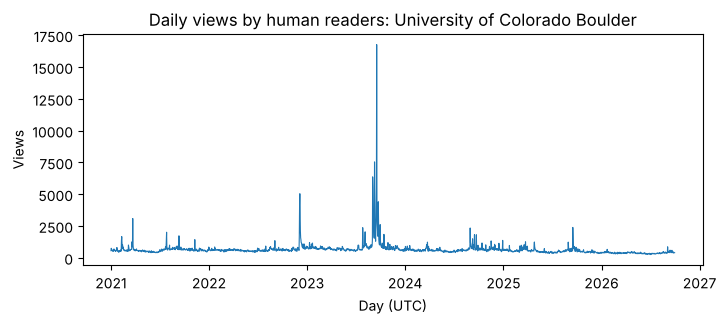

2023-09-17 16,767 views


In [15]:
# Plot views["views"] against views["timestamp"] with plt.subplots(), with a title and axis labels
# Find the day with the most views with idxmax(), and print its date and count
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(views["timestamp"], views["views"], linewidth=0.8)
ax.set_title(f"Daily views by human readers: {ARTICLE}")
ax.set_xlabel("Day (UTC)")
ax.set_ylabel("Views")
plt.show()
peak = views.loc[views["views"].idxmax()]
print(peak["timestamp"].date(), f"{peak['views']:,} views")

<details>
<summary>💬 Discuss</summary>

- The API's days are UTC days. What mistake could you make reporting the peak as a Colorado date?
- What happened around the peak? How would you check it with data, such as the revisions around that date, rather than from memory?
- A spike measures attention, not approval. Which claims can it support, and which can't it?

</details>

## Step 7 — Who is reading? (11 minutes)

A pageview is not a person. Wikimedia's [definition](https://meta.wikimedia.org/wiki/Research:Page_view) splits its counts by agent: `user` (people), `spider` (crawlers that say what they are), and `automated` (bots that don't). We need Step 5's request again for each agent, so now it earns a function: `get_pageviews()`, the chapter's, gathers Step 5's lines, with the title, dates, agent, and granularity as parameters. Call it once for each agent, with monthly granularity, for 2024 to September 2026, and plot the three together. When Wikimedia improved its bot detection in 2025, it moved past traffic from one agent to another. The chapter's ["What a Pageview Counts"](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-10-wikipedia.html#what-a-pageview-counts) has the history.

In [16]:
# Define get_pageviews(title, start, end, agent="user", granularity="daily"): Step 5's lines,
#   with title, start, end, agent, and granularity in their places in the URL
#   Return the timestamp and views columns
def get_pageviews(title, start, end, agent="user", granularity="daily"):
    article = title.replace(" ", "_")
    url = ("https://wikimedia.org/api/rest_v1/metrics/pageviews/per-article"
           f"/en.wikipedia/all-access/{agent}/{article}/{granularity}/{start}/{end}")
    response = requests.get(url, headers=HEADERS)
    views = pd.DataFrame(response.json()["items"])
    views["timestamp"] = pd.to_datetime(views["timestamp"], format="%Y%m%d%H")
    return views[["timestamp", "views"]]

In [ ]:
# For each agent in "user", "spider", "automated": get monthly views from 20240101 to 20260930,
#   add an "agent" column, and append it to a list; pause a second between requests
# Concatenate the list, pivot it to one column per agent, and print the last three months
frames = []
for agent in ["user", "spider", "automated"]:
    monthly_views = get_pageviews(ARTICLE, "20240101", "20260930", agent=agent, granularity="monthly")
    monthly_views["agent"] = agent
    frames.append(monthly_views)
    time.sleep(1)
by_agent = pd.concat(frames).pivot(index="timestamp", columns="agent", values="views")
print(by_agent.tail(3))

In [ ]:
# Plot by_agent with plt.subplots(), with a title and axis labels
fig, ax = plt.subplots(figsize=(8, 3))
by_agent.plot(ax=ax)
ax.set_title(f"Monthly views by agent: {ARTICLE}")
ax.set_xlabel("Month")
ax.set_ylabel("Views")
plt.show()

### ⏱ Microsprint (3 minutes, alone or in pairs)

**Do:** check the step's three lines. Ask `get_pageviews()` for [`agent="all-agents"`](https://doc.wikimedia.org/generated-data-platform/aqs/analytics-api/reference/page-views.html#get-number-of-page-views-for-a-page), monthly, for the same months, and check that each month is the sum of `user`, `spider`, and `automated`. Then divide `user` by it, and find the month when people were the smallest share of the views.

**Share:** whether the sum checks out, and that month and its share.

In [ ]:
# Microsprint: get monthly all-agents views for the same months; check each equals user + spider + automated
# Then divide user by all-agents, and print the month when people were the smallest share, with the share
all_agents = get_pageviews(ARTICLE, "20240101", "20260930", agent="all-agents", granularity="monthly")
total = all_agents.set_index("timestamp")["views"]
print("Sum checks out:", (by_agent.sum(axis=1) == total).all())
user_share = by_agent["user"] / total
print(f"{user_share.idxmin():%B %Y}: {user_share.min():.0%} of views were people")

<details>
<summary>💬 Discuss</summary>

- The microsprint found the month when people were the smallest share of views. How would a study that used `all-agents` have read that month?
- Wikimedia moved past traffic from one agent to another when its bot detection improved. What does that mean for anyone who downloaded counts before then?
- Our Selenium visits in week 8 came from a real browser. Which agent should they count as, and which do you think they did?

</details>

## Step 8 — Everything else is the same query (12 minutes)

Links, categories, templates, languages, and what links here are all [`action=query`](https://www.mediawiki.org/wiki/API:Query), with a different `prop` or `list`, and they all paginate the same way. A short list fits in one batch: ask with its limit at `max`, and check for `"continue"` before you trust the count. The article's categories and language editions fit, so one request gets both: `prop` takes several values joined with `|`, each with its own limit. What links here doesn't fit: for that, repeat Step 3's page two until no `"continue"` comes back. The chapter's ["Getting Links, Categories, Templates, and Languages"](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-10-wikipedia.html#getting-links-categories-templates-and-languages) wraps the same requests in `query_all()` and `page_list()`.

Look at the first few categories: some are **hidden** maintenance categories that readers never see. Add [`clshow="!hidden"`](https://www.mediawiki.org/wiki/API:Categories) to leave them out.

In [ ]:
# Ask for prop="categories|langlinks", with cllimit="max" and lllimit="max", for ARTICLE
# Print how many categories and language editions came back, whether data has a "continue",
#   and the first three categories' titles
params = {"action": "query", "titles": ARTICLE, "prop": "categories|langlinks",
          "cllimit": "max", "lllimit": "max", "format": "json"}
response = requests.get(API, params=params, headers=HEADERS)
data = response.json()
page = list(data["query"]["pages"].values())[0]
print(len(page["categories"]), "categories,", len(page["langlinks"]), "other language editions")
print("More to come:", "continue" in data)
print([c["title"] for c in page["categories"][:3]])

In [21]:
# Set params["clshow"] to "!hidden", request again, and print how many categories readers see
params["clshow"] = "!hidden"
response = requests.get(API, params=params, headers=HEADERS)
data = response.json()
page = list(data["query"]["pages"].values())[0]
print(len(page["categories"]), "categories visible to readers")

9 categories visible to readers


In [ ]:
# Ask for list=backlinks, with bltitle=ARTICLE, bllimit="max", and blnamespace=0 (articles only)
# Keep data["query"]["backlinks"] as backlinks; print how many, and whether there's a "continue"
params = {"action": "query", "list": "backlinks", "bltitle": ARTICLE,
          "bllimit": "max", "blnamespace": 0, "format": "json"}
response = requests.get(API, params=params, headers=HEADERS)
data = response.json()
backlinks = data["query"]["backlinks"]
print(len(backlinks), "so far; more to come:", "continue" in data)

In [ ]:
# While data has a "continue": pause a second, add it to params, request the next batch,
#   and extend backlinks with its ["query"]["backlinks"]
# Then print how many articles link here
while "continue" in data:
    time.sleep(1)
    params.update(data["continue"])
    response = requests.get(API, params=params, headers=HEADERS)
    data = response.json()
    backlinks.extend(data["query"]["backlinks"])
print(f"{len(backlinks):,} articles link here")

### ⏱ Microsprint (3 minutes, alone or in pairs)

**Do:** find which other titles send readers to this article. [`prop=redirects`](https://www.mediawiki.org/wiki/API:Redirects) isn't in the chapter: read its documentation for the name of its limit parameter, set it to `max`, and add `rdnamespace=0` for articles only. Check for a `"continue"` before you trust the count, and print the first eight titles. A short version of Additional Exercise 4.

**Share:** how many there are, and the most surprising one.

In [ ]:
# Microsprint: ask for prop="redirects" for ARTICLE, with its limit parameter (from the documentation)
#   set to "max", and rdnamespace=0
# Print how many titles redirect here, whether there's a "continue", and the first eight titles
params = {"action": "query", "titles": ARTICLE, "prop": "redirects",
          "rdlimit": "max", "rdnamespace": 0, "format": "json"}
response = requests.get(API, params=params, headers=HEADERS)
data = response.json()
page = list(data["query"]["pages"].values())[0]
print(len(page["redirects"]), "titles redirect here; more to come:", "continue" in data)
print([r["title"] for r in page["redirects"][:8]])

<details>
<summary>💬 Discuss</summary>

- Categories, language editions, and redirects each came in one batch, and backlinks took several. How did we know, and what would we have reported if we hadn't checked?
- Hidden categories are maintenance labels that readers never see. Should a study of how Wikipedia classifies a topic include them?
- Dozens of other editions have an article on this topic. What could you learn by comparing them, as week 6 did with French infoboxes?

</details>

## Step 9 — The same with a client library (6 minutes)

[mwclient](https://mwclient.readthedocs.io/en/latest/reference/page.html) does the continuation for you. If you haven't installed it, run `%conda install -y -c conda-forge mwclient` in a new cell first; conda-forge has version 0.10.1. Make a [`Site`](https://mwclient.readthedocs.io/en/latest/user/connecting.html#specifying-a-user-agent) with your `CLIENT` (mwclient adds its own name and version to the User-Agent), and ask it for the same article's categories, language editions, and revisions. In mwclient 0.10, `limit` is how many results to ask for in each request; version 0.11 calls it `api_chunk_size`.

Two things stay raw. mwclient speaks only the Action API, so pageviews still need Step 7's `get_pageviews()`. And it doesn't wait out a 429: it stops with an error, as the chapter's ["From Raw Requests to a Client: mwclient"](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-10-wikipedia.html#from-raw-requests-to-a-client-mwclient) says.

In [ ]:
# Import mwclient and print its version; make a Site for "en.wikipedia.org" with clients_useragent=CLIENT
# Print the User-Agent it sends (site.connection.headers["User-Agent"]); get the page from site.pages
# Count its categories, its language editions, and its revisions up to 2026-09-30T23:59:59Z,
#   500 per request (limit=500)
import mwclient
print(mwclient.__version__)
site = mwclient.Site("en.wikipedia.org", clients_useragent=CLIENT)
print(site.connection.headers["User-Agent"])
page = site.pages[ARTICLE]
print(len(list(page.categories())), "categories")
print(len(list(page.langlinks())), "language editions")
print(len(list(page.revisions(start="2026-09-30T23:59:59Z", limit=500))), "revisions")

### ⏱ Microsprint (3 minutes, alone or in pairs)

**Do:** ask mwclient for the edits that the chapter's "Getting User Contributions" got with `list=usercontribs`: Jimbo Wales's, from January to September 2026. Use [`site.usercontributions()`](https://mwclient.readthedocs.io/en/latest/reference/site.html#mwclient.client.Site.usercontributions), whose `start` is the later date, because it goes newest first. Count the edits, then count them by `ns`, the [namespace](https://www.mediawiki.org/wiki/Help:Namespaces): 0 is articles, 1 their talk pages, 3 user talk pages. This is the last part of Additional Exercise 4: the same request with mwclient.

**Share:** the total (does it match the chapter's?), and how many were edits to articles.

In [ ]:
# Microsprint: list site.usercontributions("Jimbo Wales", start="2026-09-30T23:59:59Z",
#   end="2026-01-01T00:00:00Z", limit=500) into a DataFrame
# Print how many edits, and count them by "ns" with value_counts()
contribs = pd.DataFrame(list(site.usercontributions("Jimbo Wales", start="2026-09-30T23:59:59Z",
                                                    end="2026-01-01T00:00:00Z", limit=500)))
print(f"{len(contribs)} edits")
print(contribs["ns"].value_counts())

<details>
<summary>💬 Discuss</summary>

- mwclient doesn't wait out a 429: `page.revisions()` stops partway with an `HTTPError`. What would you lose, and what does the chapter's "Common Issues to Debug" say to do?
- Most of those edits were on talk pages, not articles. What would a study that counted "edits" without splitting them by namespace get wrong?
- Week 3 was about APIs that closed. Wikipedia's has stayed open. What keeps it open, and what would your project lose if it closed?

</details>

## Step 10 — What did we learn? (5 minutes)

In a few sentences, as comments:

- Steps 3 and 9 counted the revisions two ways. Did they agree, and what would it mean if they didn't?
- In Step 7 and its microsprint, how much of the article's traffic was people? What would a study that used `all-agents` have gotten wrong?
- Which of today's numbers would be different if you ran this notebook next year, and which wouldn't? Why?
- What did mwclient do for you in Step 9 and its microsprint, and what did you still do yourself?

**Recommended Exercises ahead** (in the chapter's companion notebook, due Sunday):

- Step 1, choose an article and get its pageviews: Step 5's request, which Step 7 gathered into the chapter's `get_pageviews()`; end the window before today.
- Step 2, find the spike: Step 6's `idxmax()` and its warning about UTC days; Step 3's revisions are where to look around the date.
- Step 3, get the revision history: Step 3's three moves, ending with the chapter's `get_revisions()` and its `continue` loop.
- Step 4, profile the editors: Step 4's `value_counts()`, and its microsprint on edits without an account.
- Step 5, align edits with attention: Step 4's `resample("ME")`, and Step 7's monthly granularity.
- Step 6, map the neighborhood: Step 8's requests, which the chapter wraps in `page_list()` and `query_all()`; wikilinks are `prop=links`, with `pllimit`, and can run past 500, so check for `"continue"`.
- Step 7, interpret: the Discuss questions after Steps 4, 6, and 7.

In [31]:
# Your answers here, as comments
# 1. The revision counts weren't run live in this key: Wikipedia's 429s stopped Step 3 and Step 9 alike.
#    With rvstart and start fixed at the same moment, both should give the chapter's 2,988. If they
#    disagreed, one had stopped early or counted a different window, and only a check would tell us.
# 2. Step 7 wasn't run live either. In the chapter's printout people were 73% of September 2026's views
#    but only 51% of August's, when spiders read 9,362 times. A study using all-agents would have taken
#    August's crawler traffic for readers' interest.
# 3. Fixed windows don't change: 2,099 days and 1,367,292 human views from 2021 to September 2026, the
#    chapter's numbers exactly, and the peak, 16,767 views on 2023-09-17 (UTC). What describes the article
#    today does change: it was 95,112 bytes on 2026-10-21, against the chapter's 95,273, and readers see
#    9 of its categories. Backlinks and redirects will drift too.
# 4. mwclient follows "continue" and builds the User-Agent for us, but here Wikipedia's 429s reached it
#    too, and it stopped with an HTTPError, as the chapter warns. We still chose the time window, got pageviews
#    from the REST API ourselves, and did all the counting and plotting.

## Friday: from the lab to the textbook (15 minutes)

The last 15 minutes go to the textbook. Look back at what the lab turned up in [chapter 10](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-10-wikipedia.html):

- **An output that has changed.** The chapter printed its outputs in October 2026. Compare a few with yours, such as the article's length (Step 2) and the number of articles that link to it (Step 8). Which of them should the chapter fix to a date, and how?
- **A cell that broke.** Did a 429 stop one of your cells? The lab's code assumes every request works; the chapter's calls `raise_for_status()`, which stops with the status, and mwclient stops with an error. Where should the chapter show how to wait and try again?
- **A sentence that confused.** "Common Issues to Debug" says that a missing page's ID will be negative. What did Step 2's microsprint show?
- **A microsprint that would make a good exercise.** Checking that `all-agents` is the sum of the other three, or counting the edits made without an account, could be an Additional Exercise.

The [revision framework](https://github.com/cuinfoscience/INFO4617-Fall2026/blob/main/handouts/common/revision-framework.md) says how to propose a change, and what each kind needs to be accepted.